# KAN on alcohol deoxyfluorination with sulfonyl fluorides

**Source.** Nielsen, Ahneman, Riera, Doyle, *JACS* **2018**, *140*, 5004-5008
(DOI 10.1021/jacs.8b01523). Data and the paper's descriptors from the Doyle lab `ochem-data`
repository (`deoxyF/rxns/dft_from_paper/all.csv`).

**Reaction.** Deoxyfluorination of 37 alcohols with 5 sulfonyl fluorides and 4 organic bases:
740 reactions. The alcohol is first sulfonylated (the base deprotonates it, the sulfonyl fluoride
transfers its sulfonyl group), then the released fluoride displaces the sulfonate. Primary and
unhindered secondary alcohols follow this path cleanly; hindered and tertiary alcohols eliminate
or do not react.

**The paper's finding.** A random forest on 24 descriptors predicted yield across alcohol classes
(R$^2$ about 0.9 in the paper's held-out set) and ranked the alcohol's substitution class and the
base's descriptor as the main contributors; the best base and sulfonyl fluoride depend on the
alcohol class, which is the kind of interaction a one-descriptor rule cannot carry.

**Descriptors used here.** The paper's 24: four continuous alcohol descriptors (C1 charge, C1
exposed area, electronegativity) and sixteen 0/1 structural flags (primary, secondary, tertiary,
ring sizes, benzylic, allylic, carbonyl positions, hemiacetal, alpha-amino), one base descriptor
(N1 exposed area) and three sulfonyl fluoride charges (S1, F1, O1).

**Target.** Yield in percent, regression. Success for the threshold rules: above 40 % yield.

## What this notebook does

Every dataset notebook in this series runs the same pipeline from `pycse.sklearn.kan_interpret`,
so the results are comparable across chemistries:

1. **Models on identical folds.** A linear baseline, random forest, gradient boosting and a KAN
   scored by 5x3 repeated cross-validation with the scaler refit inside each fold, and a paired
   Wilcoxon test of the KAN against the best other model.
2. **Single-descriptor thresholds.** Class-balanced stumps scored by balanced accuracy, with the
   majority baseline, so a "rule" that only predicts the majority class scores 0.5.
3. **Partial effects with fold envelopes.** One-descriptor response curves of the KAN in the
   descriptor's own units, with the linear baseline on the same grid and the envelope of five
   refits. A shape that changes from fold to fold is not a finding.
4. **A check against the known chemistry.** What the source paper established, or (for the
   synthetic benchmark) the generating equations, overlaid on what the pipeline recovered.

No emoji, no claims from a single fit.


In [1]:
import os

os.environ["JAX_PLATFORM_NAME"] = "cpu"
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    RandomForestClassifier,
    GradientBoostingClassifier,
)
from sklearn.metrics import r2_score, mean_absolute_error, roc_auc_score, accuracy_score

from pycse.sklearn.kan import KAN
from pycse.sklearn.kan_interpret import (
    classify_shape,
    cv_compare,
    partial_effects,
    partial_effects_cv,
    plot_fold_scores,
    plot_partial_effect,
    sensitivity,
    threshold_rules,
)
from pycse.sklearn._plotstyle import (
    INK_2,
    MUTED,
    BASELINE,
    SURFACE,
    SERIES,
    PX,
    style_axes,
    finish_axes,
)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# Record the environment: KAN fits move slightly between jax/XLA builds.
import importlib.metadata as _md

print(
    "Versions:",
    ", ".join(
        f"{p} {_md.version(p)}" for p in ("pycse", "jax", "optax", "numpy", "scikit-learn", "scipy")
    ),
)


Versions: pycse 2.13.0, jax 0.12.0.1, optax 0.2.8, numpy 2.5.4, scikit-learn 1.9.1, scipy 1.18.1


## 1. Load the paper's descriptor table

Flags constant over the dataset are dropped. Flags are kept as 0/1 descriptors; their response
curves are two-point lines and are read as such.


In [2]:
URL = "https://raw.githubusercontent.com/doyle-lab-ucla/ochem-data/main/deoxyF/rxns/dft_from_paper/all.csv"
raw = pd.read_csv(URL)
X_df = raw.drop(columns=["index", "yield"]).copy()
const = [c for c in X_df.columns if X_df[c].nunique() <= 1]
X_df = X_df.drop(columns=const)
print(f"Dropped constant descriptors: {const}")
COMPONENT = {c: ("alcohol" if c.startswith("alcohol") else "base" if c.startswith("base") else "sulfonyl fluoride") for c in X_df.columns}
y = raw["yield"].to_numpy(dtype=float)
TASK = "regression"
Y_LABEL = "yield (%)"
SUCCESS = (y > 40.0).astype(int)
SUCCESS_RULE = "yield above 40 %"
n_alc = raw[[c for c in raw.columns if c.startswith("alcohol")]].drop_duplicates().shape[0]
print(f"{len(raw)} reactions: {n_alc} alcohols x {raw['base_.N1_exposed_area'].nunique()} bases x {raw['sulfonyl_fluoride_.S1_electrostatic_charge'].nunique()} sulfonyl fluorides")
cls = np.select([raw.alcohol_primary == 1, raw.alcohol_secondary == 1, raw.alcohol_tertiary == 1], ["primary", "secondary", "tertiary"], "other")
print(pd.DataFrame({"class": cls, "yield": y}).groupby("class")["yield"].agg(["mean", "count"]).round(1))


Dropped constant descriptors: []
740 reactions: 37 alcohols x 4 bases x 4 sulfonyl fluorides
           mean  count
class                 
primary    49.7    320
secondary  36.5    380
tertiary    3.3     40


740 reactions, 23 descriptors. Target: yield (%) (regression).
Success for the threshold rules: yield above 40 % (48% of reactions).


,Component,Distinct,Min,Max
alcohol_.C1_electrostatic_charge,alcohol,36,-0.112,0.808
alcohol_.C1_exposed_area,alcohol,37,0.841,16.405
alcohol_electronegativity,alcohol,9,0.090,0.170
alcohol_primary,alcohol,2,0.000,1.000
alcohol_secondary,alcohol,2,0.000,1.000
alcohol_tertiary,alcohol,2,0.000,1.000
alcohol_cyclic,alcohol,2,0.000,1.000
alcohol_4.membered_ring,alcohol,2,0.000,1.000
alcohol_5.membered_ring,alcohol,2,0.000,1.000
alcohol_6.membered_ring,alcohol,2,0.000,1.000


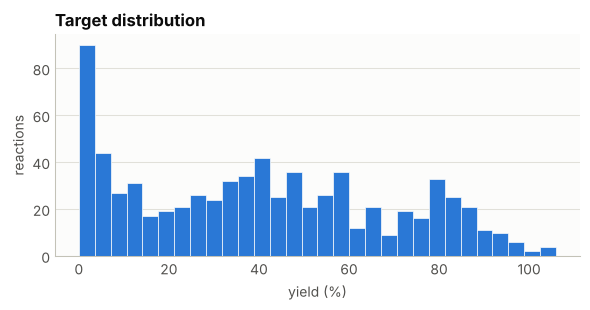

In [3]:
feature_names = list(X_df.columns)
X = X_df.to_numpy(dtype=float)
y = np.asarray(y, dtype=float)
SUCCESS = np.asarray(SUCCESS, dtype=int)
n_features = len(feature_names)
COMPONENTS = list(dict.fromkeys(COMPONENT[f] for f in feature_names))
COMP_COLOR = {c: SERIES[k % len(SERIES)] for k, c in enumerate(COMPONENTS)}

desc = pd.DataFrame(
    {
        "Component": [COMPONENT[f] for f in feature_names],
        "Distinct": X_df.nunique().values,
        "Min": X_df.min().values,
        "Max": X_df.max().values,
    },
    index=feature_names,
)
print(f"{len(X)} reactions, {n_features} descriptors. Target: {Y_LABEL} ({TASK}).")
print(f"Success for the threshold rules: {SUCCESS_RULE} ({SUCCESS.mean():.0%} of reactions).")
display(desc.round(3))

fig, ax = plt.subplots(figsize=(6, 3.2))
style_axes(ax)
if TASK == "regression":
    ax.hist(y, bins=30, color=SERIES[0], edgecolor=SURFACE, linewidth=0.5)
    finish_axes(ax, "Target distribution", Y_LABEL, "reactions")
else:
    vals, counts = np.unique(y, return_counts=True)
    ax.bar(vals, counts, width=0.6, color=[MUTED, SERIES[0]], linewidth=0)
    ax.set_xticks(vals)
    ax.set_xticklabels([f"{int(v)} ({c})" for v, c in zip(vals, counts)])
    finish_axes(ax, "Class balance", Y_LABEL, "reactions")
plt.tight_layout()
plt.show()


## 2. Models on identical folds

The four models see exactly the same 15 folds (5 splits x 3 repeats, scaler refit per fold).
The paired comparison asks a narrow question: on the same held-out reactions, is the KAN better
than the best of the other models, and how often?


Model                  r2               other
MLR                    0.497 ± 0.047   16.169 ± 0.700 (mae)
Random Forest          0.908 ± 0.011   6.183 ± 0.379 (mae)
Gradient Boosting      0.931 ± 0.015   5.545 ± 0.411 (mae)
KAN                    0.865 ± 0.022   7.792 ± 0.367 (mae)
KAN vs Gradient Boosting, paired over 15 folds: Δr2 = -0.0657 ± 0.0157, KAN better in 0/15, Wilcoxon p = 6.1e-05
(107 s)


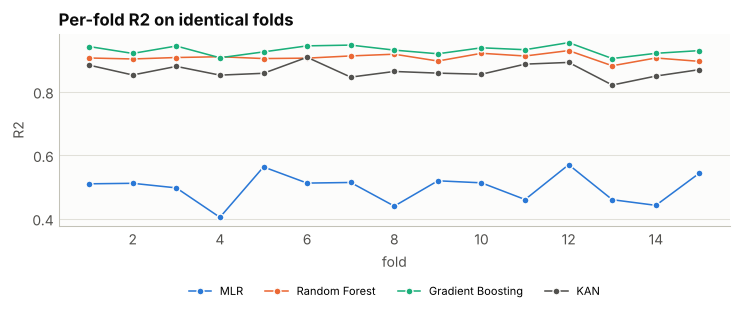

In [4]:
# One hidden layer; width 8 and 5 knots on datasets of 1000 reactions or more,
# 4 and 3 below that, so the spline count stays in proportion to the data.
WIDE = len(X) >= 1000
KAN_LAYERS = (n_features, 8 if WIDE else 4, 1)
KAN_GRID = 5 if WIDE else 3
KAN_MAXITER = 300
CV_SPLITS, CV_REPEATS, CV_SEED = 5, 3, 42


def make_kan():
    return KAN(layers=KAN_LAYERS, grid_size=KAN_GRID, spline_order=3)


def make_models():
    """Fresh models; the ensembles use the settings of the first two chemistry notebooks."""
    if TASK == "regression":
        return {
            "MLR": LinearRegression(),
            "Random Forest": RandomForestRegressor(
                n_estimators=300, max_depth=12, min_samples_split=5, min_samples_leaf=2,
                random_state=42, n_jobs=-1,
            ),  # fmt: skip
            "Gradient Boosting": GradientBoostingRegressor(
                n_estimators=300, learning_rate=0.1, max_depth=4, min_samples_split=5,
                min_samples_leaf=3, subsample=0.8, random_state=42,
            ),  # fmt: skip
            "KAN": make_kan(),
        }
    return {
        "Logistic": LogisticRegression(max_iter=2000),
        "Random Forest": RandomForestClassifier(
            n_estimators=300, max_depth=12, min_samples_split=5, min_samples_leaf=2,
            random_state=42, n_jobs=-1,
        ),  # fmt: skip
        "Gradient Boosting": GradientBoostingClassifier(
            n_estimators=300, learning_rate=0.1, max_depth=4, min_samples_split=5,
            min_samples_leaf=3, subsample=0.8, random_state=42,
        ),  # fmt: skip
        "KAN": make_kan(),
    }


BASELINE_NAME = "MLR" if TASK == "regression" else "Logistic"

t0 = time.time()
cv_result = cv_compare(
    make_models(),
    X,
    y,
    task=TASK,
    n_splits=CV_SPLITS,
    n_repeats=CV_REPEATS,
    random_state=CV_SEED,
    fit_kwargs={"KAN": {"maxiter": KAN_MAXITER}},
    verbose=False,
)
print(cv_result)
print(f"({time.time() - t0:.0f} s)")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
plot_fold_scores(ax, cv_result)
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.25))
plt.tight_layout()
plt.show()


Held-out split: 592 train / 148 test


,Test R2,Test MAE
Model,,
MLR,0.510,16.678
Random Forest,0.909,6.339
Gradient Boosting,0.940,5.543
KAN,0.885,7.625


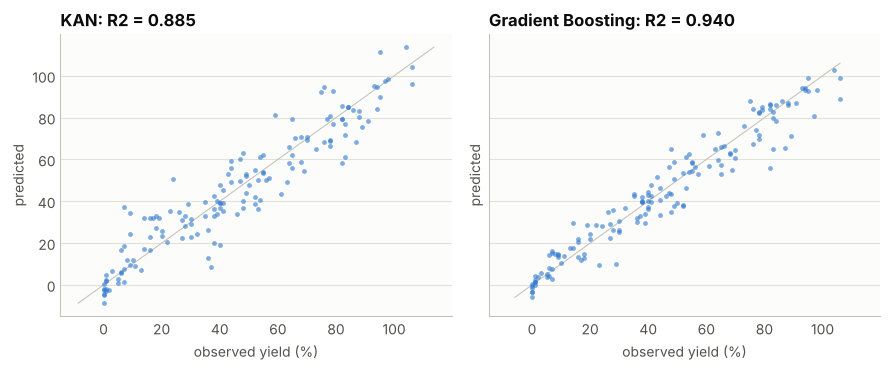

In [5]:
# One held-out split for the models the rest of the notebook interprets.
strat = y.astype(int) if TASK == "classification" else None
idx_tr, idx_te = train_test_split(np.arange(len(X)), test_size=0.2, random_state=42, stratify=strat)
scaler = StandardScaler().fit(X[idx_tr])
X_tr, X_te = scaler.transform(X[idx_tr]), scaler.transform(X[idx_te])
y_tr, y_te = y[idx_tr], y[idx_te]

fitted, rows = {}, []
for name, model in make_models().items():
    if name == "KAN":
        model.fit(X_tr, y_tr, maxiter=KAN_MAXITER)
    else:
        model.fit(X_tr, y_tr.astype(int) if TASK == "classification" else y_tr)
    fitted[name] = model
    if TASK == "regression":
        p = model.predict(X_te)
        rows.append({"Model": name, "Test R2": r2_score(y_te, p), "Test MAE": mean_absolute_error(y_te, p)})
    else:
        p = model.predict_proba(X_te)[:, 1] if hasattr(model, "predict_proba") else np.clip(model.predict(X_te), 0, 1)
        rows.append({"Model": name, "Test AUC": roc_auc_score(y_te, p), "Test accuracy": accuracy_score(y_te, (p > 0.5).astype(int))})
kan, baseline = fitted["KAN"], fitted[BASELINE_NAME]


def model_means(labels, model=None):
    """Observed and predicted mean target per group, over the training reactions.

    A partial effect fixes the other descriptors at their mean, which is not a real
    compound; to compare a model with observed group means, average its predictions
    over the reactions that were actually run.
    """
    model = model or kan
    pred = np.ravel(model.predict(X_tr))
    lab = np.asarray(labels)[idx_tr]
    return (
        pd.DataFrame({"label": lab, "observed": y[idx_tr], "predicted": pred})
        .groupby("label")
        .agg(observed=("observed", "mean"), predicted=("predicted", "mean"), n=("observed", "size"))
    )
headline = pd.DataFrame(rows).set_index("Model")
print(f"Held-out split: {len(idx_tr)} train / {len(idx_te)} test")
display(headline.round(3))

# The KAN against the best other model on the held-out reactions
metric = "Test R2" if TASK == "regression" else "Test AUC"
best_other = headline.drop("KAN")[metric].idxmax()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharex=True, sharey=True)
for ax, name in zip(axes, ["KAN", best_other]):
    style_axes(ax)
    m = fitted[name]
    if TASK == "regression":
        p = m.predict(X_te)
        lim = [min(y_te.min(), p.min()), max(y_te.max(), p.max())]
        ax.plot(lim, lim, color=BASELINE, linewidth=PX, zorder=1)
        ax.scatter(y_te, p, s=12, color=SERIES[0], alpha=0.6, linewidths=0, zorder=2)
        finish_axes(ax, f"{name}: R2 = {headline.loc[name, metric]:.3f}", f"observed {Y_LABEL}", "predicted")
    else:
        p = m.predict_proba(X_te)[:, 1] if hasattr(m, "predict_proba") else np.clip(m.predict(X_te), 0, 1)
        bins = np.linspace(0, 1, 21)
        ax.hist(p[y_te == 0], bins=bins, color=MUTED, alpha=0.7, label="observed 0", linewidth=0)
        ax.hist(p[y_te == 1], bins=bins, color=SERIES[0], alpha=0.7, label="observed 1", linewidth=0)
        ax.legend(frameon=False, fontsize=8)
        finish_axes(ax, f"{name}: AUC = {headline.loc[name, metric]:.3f}", "predicted probability", "reactions")
plt.tight_layout()
plt.show()


## 3. Single-descriptor thresholds

The Doyle and Sigman groups look for reactivity cliffs with one cut on one descriptor. The same
search here: a depth-1 tree with balanced class weights on each descriptor, scored on the held-out
reactions by balanced accuracy. A descriptor with no information scores 0.5 whatever the class
balance.


Majority-class accuracy on the test reactions: 0.534
Balanced-accuracy baseline for guessing: 0.500


,Feature,Threshold,Balanced_Acc,Accuracy,Precision,Recall
0,alcohol_.C1_electrostatic_charge,0.198,0.635,0.635,0.667,0.633
1,alcohol_cyclic,0.500,0.608,0.622,0.610,0.810
2,base_.N1_exposed_area,6.733,0.604,0.622,0.602,0.861
3,alcohol_benzylic,0.500,0.583,0.568,0.683,0.354
4,alcohol_.C1_exposed_area,12.267,0.580,0.574,0.629,0.494
5,sulfonyl_fluoride_.O1_electrostatic_charge,-0.392,0.579,0.561,0.706,0.304
6,sulfonyl_fluoride_.F1_electrostatic_charge,-0.180,0.579,0.561,0.706,0.304
7,alcohol_6.membered_ring,0.500,0.575,0.601,0.576,0.962
8,alcohol_allylic,0.500,0.573,0.601,0.574,0.987
9,alcohol_alpha.amino,0.500,0.560,0.534,0.778,0.177


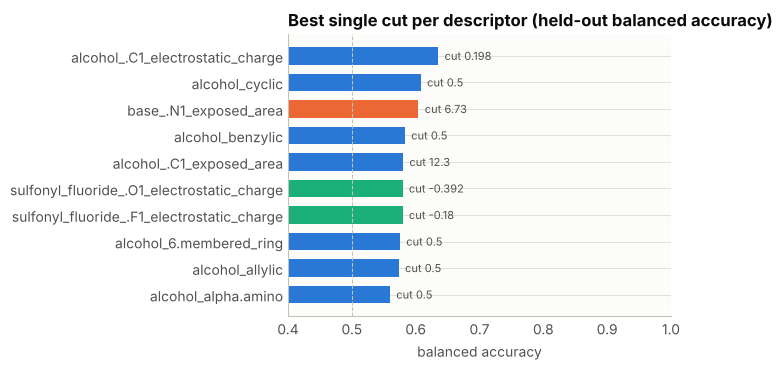

In [6]:
rules = threshold_rules(X[idx_tr], SUCCESS[idx_tr], feature_names, X[idx_te], SUCCESS[idx_te])
print(f"Majority-class accuracy on the test reactions: {rules.attrs['majority_accuracy']:.3f}")
print("Balanced-accuracy baseline for guessing: 0.500")
display(rules.head(10).round(3))

top = rules.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 3.8))
style_axes(ax)
ax.barh(top.Feature, top.Balanced_Acc, color=[COMP_COLOR[COMPONENT[f]] for f in top.Feature], height=0.65, linewidth=0)
ax.axvline(0.5, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_xlim(0.4, 1.0)
for yk, (f, b, t) in enumerate(zip(top.Feature, top.Balanced_Acc, top.Threshold)):
    ax.text(b + 0.01, yk, f"cut {t:.3g}", va="center", fontsize=8, color=INK_2)
finish_axes(ax, "Best single cut per descriptor (held-out balanced accuracy)", "balanced accuracy", "")
plt.tight_layout()
plt.show()


## 4. Partial effects with fold envelopes

Sensitivity ranks the descriptors by how much the KAN prediction moves per standardized unit,
averaged over the training reactions. The top descriptors get a response curve in their own units
(the other descriptors at their mean), the linear baseline on the same grid, and the envelope of
five refits on disjoint folds. The support strip along the bottom shows where the data are.


,Feature,Component,Sensitivity
0,alcohol_electronegativity,alcohol,42.4856
1,sulfonyl_fluoride_.S1_electrostatic_charge,sulfonyl fluoride,37.5701
2,alcohol_.C1_electrostatic_charge,alcohol,29.7263
3,alcohol_tertiary,alcohol,20.0571
4,sulfonyl_fluoride_.O1_electrostatic_charge,sulfonyl fluoride,16.7990
5,alcohol_.C1_exposed_area,alcohol,15.9232
6,alcohol_alpha.carbonyl,alcohol,14.5596
7,alcohol_alpha.amino,alcohol,14.4746
8,sulfonyl_fluoride_.F1_electrostatic_charge,sulfonyl fluoride,13.6593
9,alcohol_6.membered_ring,alcohol,12.6039


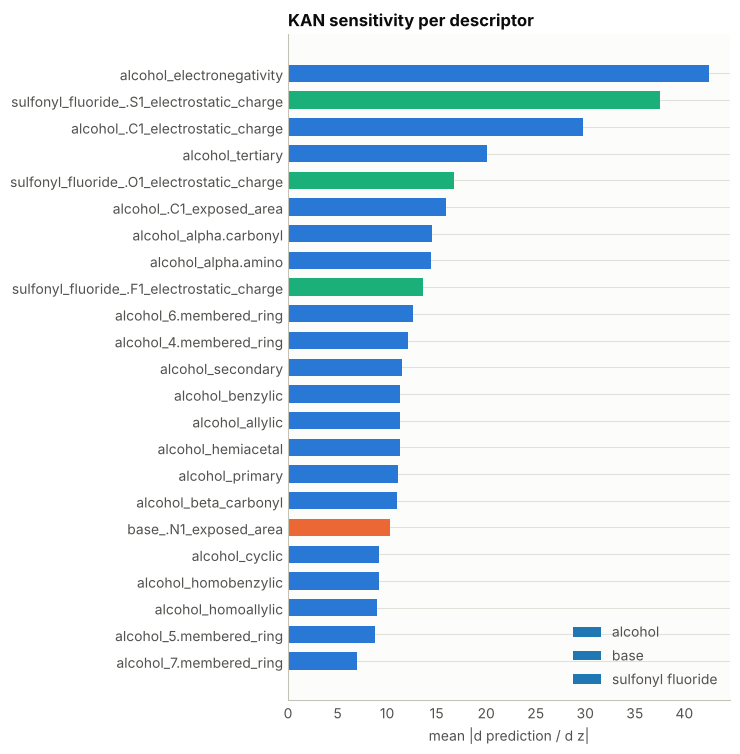

5 descriptors with at least 5 distinct values; 18 with fewer, shown as levels below.


fold envelopes: 26 s


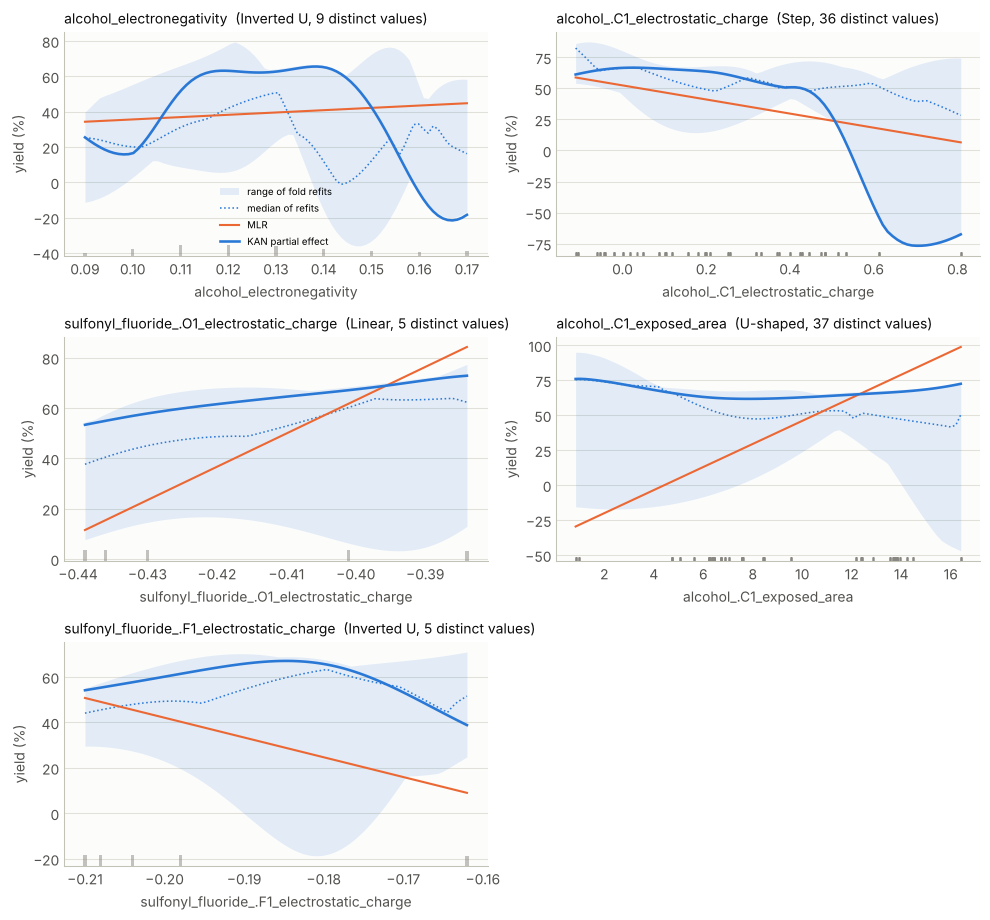

In [7]:
sens = sensitivity(kan, X_tr, task=TASK)
sens_df = pd.DataFrame(
    {"Feature": feature_names, "Component": [COMPONENT[f] for f in feature_names], "Sensitivity": sens}
).sort_values("Sensitivity", ascending=False).reset_index(drop=True)
display(sens_df.round(4))

fig, ax = plt.subplots(figsize=(7.5, 0.28 * n_features + 1.2))
style_axes(ax)
sd = sens_df.iloc[::-1]
ax.barh(sd.Feature, sd.Sensitivity, color=[COMP_COLOR[c] for c in sd.Component], height=0.65, linewidth=0)
for c in COMPONENTS:
    ax.barh([], [], color=COMP_COLOR[c], label=c)
ax.legend(frameon=False, fontsize=8, loc="lower right")
finish_axes(ax, "KAN sensitivity per descriptor", "mean |d prediction / d z|", "")
plt.tight_layout()
plt.show()

# A response curve needs values to interpolate between. Descriptors with fewer
# than five distinct values are handled as levels in the next cell instead.
MIN_LEVELS = 5
rich = [f for f in feature_names if X_df[f].nunique() >= MIN_LEVELS]
few = [f for f in feature_names if f not in rich]
top_features = sens_df[sens_df.Feature.isin(rich)].Feature.head(8).tolist()
TOP_K = len(top_features)
print(f"{len(rich)} descriptors with at least {MIN_LEVELS} distinct values; {len(few)} with fewer, shown as levels below.")
effects = partial_effects(
    kan, X[idx_tr], feature_names, top_features, scaler=scaler, task=TASK,
    extra_models={BASELINE_NAME: baseline},
)  # fmt: skip
t0 = time.time()
effects = partial_effects_cv(
    make_kan, X, y, feature_names, top_features, task=TASK, n_splits=5, random_state=42,
    fit_kwargs={"maxiter": KAN_MAXITER}, effects=effects, verbose=False,
)  # fmt: skip
print(f"fold envelopes: {time.time() - t0:.0f} s")

ncol = 2
nrow = int(np.ceil(TOP_K / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(10, 3.1 * nrow))
for ax, f in zip(np.ravel(axes), top_features):
    plot_partial_effect(ax, effects[f], ylabel=Y_LABEL)
    ax.set_title(f"{f}  ({effects[f].shape(scale=y.std() if TASK == 'regression' else 1.0)[0]}, {effects[f].n_unique} distinct values)", loc="left", fontsize=10)
for ax in np.ravel(axes)[TOP_K:]:
    ax.axis("off")
for ax in np.ravel(axes)[1:TOP_K]:  # one legend is enough
    if ax.get_legend():
        ax.get_legend().remove()
np.ravel(axes)[0].legend(frameon=False, fontsize=7, loc="best")
plt.tight_layout()
plt.show()


In [8]:
# Descriptors with four or fewer levels. A response curve needs a grid; these get a
# table instead: the observed mean per level and the model's mean prediction over the
# same reactions (not at an averaged molecule, which is not a real compound).
if few:
    pred_tr = np.ravel(kan.predict(X_tr))
    rows = []
    for f in few:
        j = feature_names.index(f)
        for lvl in np.unique(X[:, j]):
            at = X[idx_tr, j] == lvl
            rows.append(
                {
                    "Feature": f,
                    "Component": COMPONENT[f],
                    "Level": lvl,
                    "Reactions": int((X[:, j] == lvl).sum()),
                    "Observed mean": float(y[X[:, j] == lvl].mean()),
                    "KAN mean prediction": float(pred_tr[at].mean()) if at.any() else np.nan,
                }
            )
    levels = pd.DataFrame(rows)
    display(levels.round(3))
    spread = levels.groupby("Feature")["Observed mean"].agg(lambda s: s.max() - s.min())
    print("Observed spread across the levels of each few-level descriptor:")
    print(spread.round(1).sort_values(ascending=False).to_string())
else:
    levels = pd.DataFrame()
    print("Every descriptor has at least five distinct values; nothing to show here.")


,Feature,Component,Level,Reactions,Observed mean,KAN mean prediction
0,alcohol_primary,alcohol,0.000,420,33.362,31.841
1,alcohol_primary,alcohol,1.000,320,49.678,48.938
2,alcohol_secondary,alcohol,0.000,360,44.528,43.441
3,alcohol_secondary,alcohol,1.000,380,36.524,35.078
4,alcohol_tertiary,alcohol,0.000,700,42.537,41.337
5,alcohol_tertiary,alcohol,1.000,40,3.325,2.703
6,alcohol_cyclic,alcohol,0.000,500,45.922,44.721
7,alcohol_cyclic,alcohol,1.000,240,28.950,27.885
8,alcohol_4.membered_ring,alcohol,0.000,720,40.950,39.892
9,alcohol_4.membered_ring,alcohol,1.000,20,21.250,12.971


Observed spread across the levels of each few-level descriptor:
Feature
alcohol_tertiary                              39.2
alcohol_homoallylic                           38.4
alcohol_beta_carbonyl                         33.9
alcohol_6.membered_ring                       26.5
alcohol_allylic                               26.1
alcohol_4.membered_ring                       19.7
alcohol_cyclic                                17.0
sulfonyl_fluoride_.S1_electrostatic_charge    16.7
alcohol_primary                               16.3
base_.N1_exposed_area                         14.0
alcohol_benzylic                              13.4
alcohol_alpha.carbonyl                        11.6
alcohol_homobenzylic                          11.0
alcohol_alpha.amino                           10.9
alcohol_7.membered_ring                       10.6
alcohol_secondary                              8.0
alcohol_hemiacetal                             6.0
alcohol_5.membered_ring                        0.8


In [9]:
# Shape of the single fit, and whether the five refits agree on it. A curve whose
# range is under 5 % of the target's spread is "Constant" whatever its wiggles.
SHAPE_SCALE = y.std() if TASK == "regression" else 1.0


def stability_table(effects):
    rows = []
    for f, pe in effects.items():
        label, note = pe.shape(scale=SHAPE_SCALE)
        fold_labels = [classify_shape(pe.x_std, c, scale=SHAPE_SCALE)[0] for c in pe.curves]
        agree = float(np.mean([lab == label for lab in fold_labels]))
        width = float(np.mean(pe.hi - pe.lo) / (np.ptp(pe.median) + 1e-9))
        rows.append(
            {
                "Feature": f,
                "Component": COMPONENT[f],
                "Shape": label,
                "Nonlinearity": pe.nonlinearity(),
                "Fold agreement": agree,
                "Envelope / range": width,
                "Fold shapes": ", ".join(fold_labels),
            }
        )
    return pd.DataFrame(rows)


stab = stability_table(effects)
display(stab.round(3))
stable = stab[(stab["Fold agreement"] >= 0.8) & (stab["Envelope / range"] < 0.5)]
print("Shapes that survive refitting (4/5 folds agree, refits disagree by less than half the curve range):")
for _, r in stable.iterrows():
    print(f"  {r.Feature}: {r.Shape}")
print("Shapes that do not:")
for _, r in stab.drop(stable.index).iterrows():
    print(f"  {r.Feature}: single fit {r.Shape}; folds {r['Fold shapes']}")


,Feature,Component,Shape,Nonlinearity,Fold agreement,Envelope / range,Fold shapes
0,alcohol_electronegativity,alcohol,Inverted U,0.943,0.2,1.293,"Inverted U, Complex, Complex, Complex, Complex"
1,alcohol_.C1_electrostatic_charge,alcohol,Step,0.484,0.2,1.233,"Step, Complex, Linear, Complex, Complex"
2,sulfonyl_fluoride_.O1_electrostatic_charge,sulfonyl fluoride,Linear,0.075,0.4,2.157,"Linear, Linear, Complex, Inverted U, Complex"
3,alcohol_.C1_exposed_area,alcohol,U-shaped,0.956,0.2,2.164,"U-shaped, Complex, Step, Step, Linear"
4,sulfonyl_fluoride_.F1_electrostatic_charge,sulfonyl fluoride,Inverted U,0.912,0.2,3.050,"Inverted U, Linear, Complex, Step, Complex"


Shapes that survive refitting (4/5 folds agree, refits disagree by less than half the curve range):
Shapes that do not:
  alcohol_electronegativity: single fit Inverted U; folds Inverted U, Complex, Complex, Complex, Complex
  alcohol_.C1_electrostatic_charge: single fit Step; folds Step, Complex, Linear, Complex, Complex
  sulfonyl_fluoride_.O1_electrostatic_charge: single fit Linear; folds Linear, Linear, Complex, Inverted U, Complex
  alcohol_.C1_exposed_area: single fit U-shaped; folds U-shaped, Complex, Step, Step, Linear
  sulfonyl_fluoride_.F1_electrostatic_charge: single fit Inverted U; folds Inverted U, Linear, Complex, Step, Complex


## 5. Check against the chemistry

Three mechanism-level expectations: tertiary alcohols should fail (elimination beats S$_N$2),
the base effect should depend on the alcohol class, and the sulfonyl fluoride's electrophilicity
(S1 charge) should matter for the sulfonylation step. The cells below take the group means
straight from the data and put the base and sulfonyl fluoride means beside the KAN curves.


Mean yield by alcohol class and base (N1 exposed area):
base       4.727  5.305  6.069  7.397
class                                
primary     57.9   60.0   48.9   31.9
secondary   36.7   36.6   39.8   33.0
tertiary     2.5    3.3    4.6    2.9

Mean yield by alcohol class and sulfonyl fluoride (S1 charge):
SF         0.849  0.926  0.973  0.978
class                                
primary     45.5   51.3   49.4   52.8
secondary   29.7   56.1   30.8   35.2
tertiary     1.4   12.2    0.9    1.1


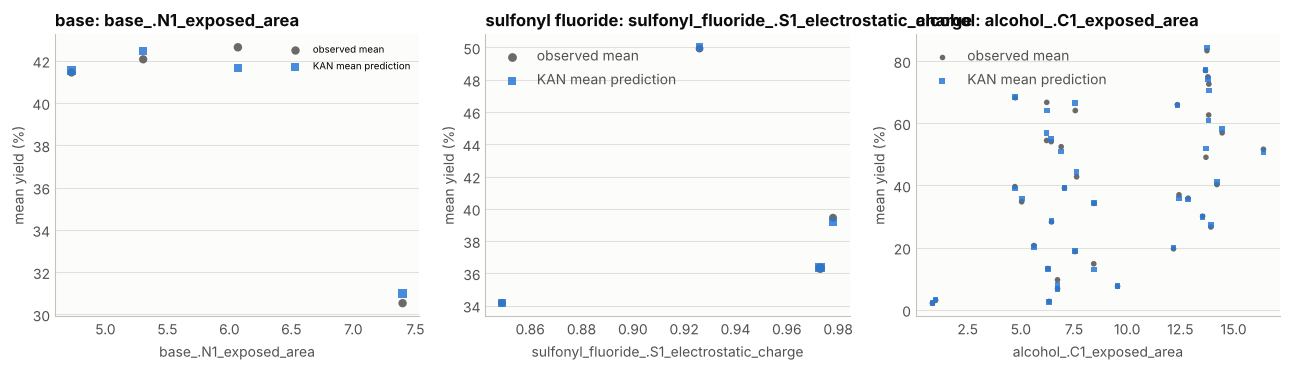

In [10]:
cls = pd.Series(np.select([raw.alcohol_primary == 1, raw.alcohol_secondary == 1, raw.alcohol_tertiary == 1], ["primary", "secondary", "tertiary"], "other"), index=raw.index)
print("Mean yield by alcohol class and base (N1 exposed area):")
print(pd.DataFrame({"class": cls, "base": raw["base_.N1_exposed_area"], "yield": y}).pivot_table(index="class", columns="base", values="yield", aggfunc="mean").round(1))
print("\nMean yield by alcohol class and sulfonyl fluoride (S1 charge):")
print(pd.DataFrame({"class": cls, "SF": raw["sulfonyl_fluoride_.S1_electrostatic_charge"], "yield": y}).pivot_table(index="class", columns="SF", values="yield", aggfunc="mean").round(1))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col, lab in zip(axes, ["base_.N1_exposed_area", "sulfonyl_fluoride_.S1_electrostatic_charge", "alcohol_.C1_exposed_area"],
                        ["base", "sulfonyl fluoride", "alcohol"]):  # fmt: skip
    style_axes(ax)
    mm = model_means(raw[col])
    ax.scatter(mm.index, mm.observed, s=14 + 0.15 * mm.n, color=INK_2, alpha=0.85, linewidths=0, zorder=3, label="observed mean")
    ax.scatter(mm.index, mm.predicted, s=14 + 0.15 * mm.n, marker="s", color=SERIES[0], alpha=0.85, linewidths=0, zorder=4, label="KAN mean prediction")
    finish_axes(ax, f"{lab}: {col}", col, "mean yield (%)")
axes[0].legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.show()


### Reading

This dataset is carried by structural flags, and the flags say what the mechanism says.

**Substitution class decides the outcome.** Tertiary alcohols average 3.3 % yield against 42.5 %
for everything else, the largest level difference in the dataset. Primary alcohols average 49.7 %
and secondary 36.5 %. Deoxyfluorination here runs through a sulfonate that fluoride then displaces
in a backside attack, so a tertiary center eliminates instead of substituting. The KAN reproduces
every level mean to within about one point.

**The other flags are consistent with that picture.** Homoallylic alcohols (3.1 %), those with a
carbonyl beta to the alcohol (7.5 %) and six-membered cyclic alcohols (17.5 %) are the weak cases;
benzylic (50.9 %) and alpha-carbonyl (51.4 %) alcohols are the strong ones. Each of these rests on
20 to 160 reactions, so they are group means, not fits.

**The base effect depends on the alcohol, which is the paper's point.** Primary alcohols fall from
57.9 % with the smallest base to 31.9 % with the largest, while secondary alcohols barely move,
36.7 to 33.0 %. A single-descriptor rule cannot carry an effect whose sign depends on another
component, and this is the clearest interaction in the series.

**No continuous descriptor curve survives refitting.** The five continuous descriptors all change
shape from fold to fold, agreeing on only one or two of five refits, with envelopes 1.2 to 3.1
times the curve range. With 37 alcohols behind
three continuous alcohol descriptors, that is the expected result: the information is in the
discrete structural classes, and the notebook reports it there.

**Models.** Gradient boosting reaches cross-validated R2 0.931, the random forest 0.908, the KAN
0.865 and the linear model 0.497. The KAN loses to gradient boosting in 15 folds of 15, by the
widest margin in the series. A dataset carried by sixteen binary flags suits a tree, not splines.


## 6. Summary dashboard

Four tiles, all from the numbers above: cross-validated score per model, the best single cuts,
the sensitivity grouped by reaction component, and the stability of the top response curves.


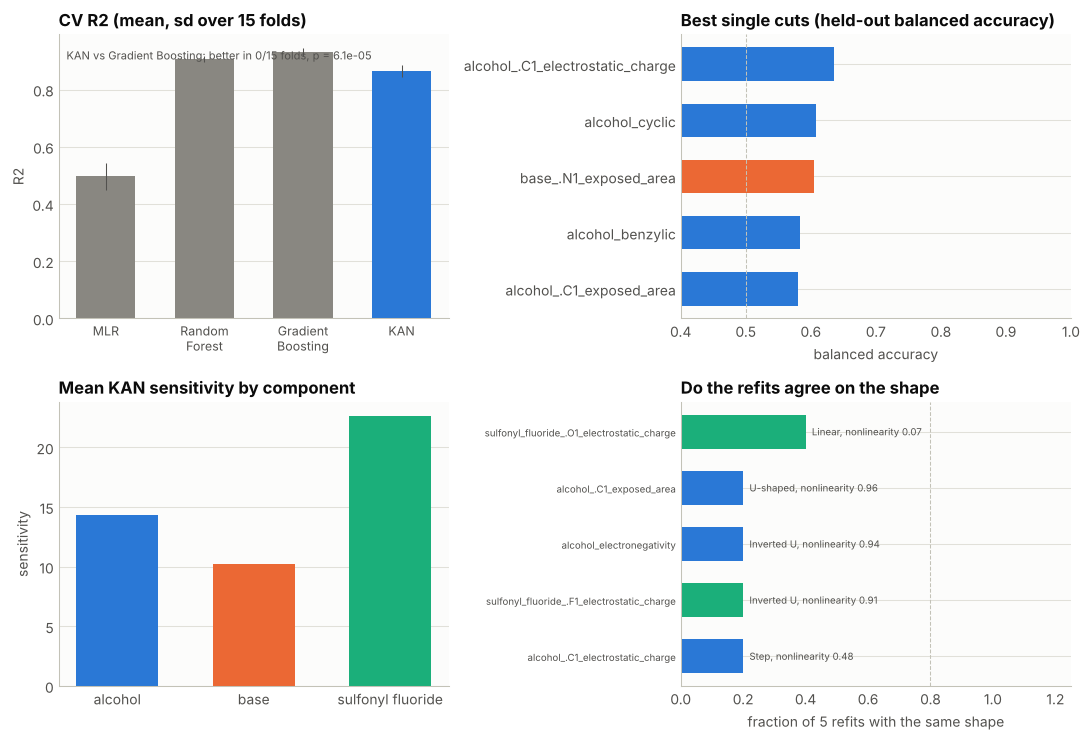

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
ax = axes[0, 0]
style_axes(ax)
s = cv_result.summary
names = list(s.index)
ax.bar(names, s[cv_result.metric + "_mean"], yerr=s[cv_result.metric + "_std"], color=[MUTED] * (len(names) - 1) + [SERIES[0]], width=0.6, linewidth=0, error_kw={"elinewidth": PX, "ecolor": INK_2})
ax.set_xticks(range(len(names)))
ax.set_xticklabels([n.replace(" ", "\n") for n in names], fontsize=9)
p = cv_result.pairwise
finish_axes(ax, f"CV {cv_result.metric.upper()} (mean, sd over {CV_SPLITS * CV_REPEATS} folds)", "", cv_result.metric.upper())
ax.text(0.02, 0.95, f"KAN vs {p['vs']}: better in {p['wins']}/{p['n']} folds, p = {p['p']:.2g}", transform=ax.transAxes, va="top", fontsize=8, color=INK_2)

ax = axes[0, 1]
style_axes(ax)
top5 = rules.head(5).iloc[::-1]
ax.barh(top5.Feature, top5.Balanced_Acc, color=[COMP_COLOR[COMPONENT[f]] for f in top5.Feature], height=0.6, linewidth=0)
ax.axvline(0.5, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_xlim(0.4, 1.0)
finish_axes(ax, "Best single cuts (held-out balanced accuracy)", "balanced accuracy", "")

ax = axes[1, 0]
style_axes(ax)
comp_sens = sens_df.groupby("Component")["Sensitivity"].mean().reindex(COMPONENTS)
ax.bar(comp_sens.index, comp_sens.values, color=[COMP_COLOR[c] for c in comp_sens.index], width=0.6, linewidth=0)
finish_axes(ax, "Mean KAN sensitivity by component", "", "sensitivity")

ax = axes[1, 1]
style_axes(ax)
st = stab.sort_values(["Fold agreement", "Nonlinearity"])
ax.barh(st.Feature, st["Fold agreement"], color=[COMP_COLOR[c] for c in st.Component], height=0.6, linewidth=0)
ax.axvline(0.8, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_xlim(0, 1.25)
for yk, (a, nl, sh) in enumerate(zip(st["Fold agreement"], st["Nonlinearity"], st.Shape)):
    ax.text(a + 0.02, yk, f"{sh}, nonlinearity {nl:.2f}", va="center", fontsize=7, color=INK_2)
ax.tick_params(axis="y", labelsize=7)
finish_axes(ax, "Do the refits agree on the shape", "fraction of 5 refits with the same shape", "")
plt.tight_layout()
plt.show()
